# Predição de AVC — APS2: Avaliação, interpretação e discussão

**Aluno:** Matheus Henrique Pereira Borba · **Entrega (APS2):** 30/10/2026

**Dataset:** [Stroke Prediction Dataset](https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset) (Kaggle, fedesoriano)

Seções 2 a 4 da APS2. Usa os modelos ajustados e salvos pelo notebook 03. O conjunto de teste é usado aqui pela primeira vez, e **nenhuma decisão de modelagem é tomada com ele**: o modelo, os hiperparâmetros e o limiar já estão fixos. As análises sobre o teste servem só para avaliar e explicar.

## Setup

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import (PrecisionRecallDisplay, RocCurveDisplay, accuracy_score, average_precision_score,
                             confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score)

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False,
                                     "axes.titleweight": "bold", "legend.frameon": False, "figure.dpi": 110})

AZUL, LARANJA, VIOLETA, CINZA = "#2a78d6", "#eb6834", "#4a3aa7", "#898781"
TARGET = "stroke"

# Nomes legíveis das features transformadas, usados nos gráficos de interpretação
ROTULOS = {
    "age": "idade", "avg_glucose_level": "glicose média", "bmi": "IMC", "missingindicator_bmi": "IMC ausente",
    "hypertension": "hipertensão", "heart_disease": "doença cardíaca", "gender_Male": "gênero masculino",
    "ever_married_Yes": "já foi casado(a)", "Residence_type_Urban": "área urbana",
    "work_type_Govt_job": "trabalho: público", "work_type_Never_worked": "trabalho: nunca trabalhou",
    "work_type_Private": "trabalho: privado", "work_type_Self-employed": "trabalho: autônomo",
    "work_type_children": "trabalho: criança",
    "smoking_status_Unknown": "tabagismo: desconhecido", "smoking_status_formerly smoked": "tabagismo: ex-fumante",
    "smoking_status_never smoked": "tabagismo: nunca fumou", "smoking_status_smokes": "tabagismo: fuma",
}

C:\dev\Projetos\Insper\APS-ML\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Carregamento

In [2]:
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = ROOT / "data" / "processed"

train, test = pd.read_csv(PROCESSED / "train.csv"), pd.read_csv(PROCESSED / "test.csv")
X_train, y_train = train.drop(columns=TARGET), train[TARGET]
X_test, y_test = test.drop(columns=TARGET), test[TARGET]

# Modelos salvos pelo notebook 03
modelos = joblib.load(ROOT / "models" / "modelos.joblib")
modelo_final = modelos["modelo_final"]         # Random Forest + limiar
pipeline_rf = modelo_final.estimator_          # pipeline (pré-processamento + floresta) sem o limiar
logistica = modelos["logistica"]
LIMIAR = modelo_final.threshold

print(f"teste {X_test.shape}, {y_test.sum()} casos de AVC ({y_test.mean():.1%})")
print(f"Modelo final: {pipeline_rf['modelo']}, {pipeline_rf['prep'].get_feature_names_out().size} features, "
      f"limiar {LIMIAR:.3f}")

teste (1022, 10), 50 casos de AVC (4.9%)
Modelo final: RandomForestClassifier(max_depth=5, min_samples_leaf=5, n_estimators=300,
                       random_state=42), 11 features, limiar 0.090


# Seção 2 — Avaliação do melhor modelo no conjunto de teste

### 2.1 Métricas

As métricas pedidas (accuracy, precision, recall e F1 da classe AVC), mais ROC-AUC e PR-AUC, que não dependem do limiar. Três linhas de referência: o Dummy, a mesma floresta com o limiar padrão de 0,5 e a regressão logística ajustada. A logística entra só para comparação, com as métricas que não dependem de limiar; ela não substitui o modelo escolhido, porque isso seria escolher modelo olhando o teste.

In [3]:
proba = modelo_final.predict_proba(X_test)[:, 1]          # probabilidade de AVC
previsto = modelo_final.predict(X_test).astype(bool)      # decisão com o limiar de 0,090
proba_dummy = modelos["dummy"].predict_proba(X_test)[:, 1]
proba_logistica = logistica.predict_proba(X_test)[:, 1]


def metricas(y_previsto, y_proba):
    """Métricas pedidas no enunciado (classe positiva = AVC) e as duas que não dependem do limiar."""
    limiar = {} if y_previsto is None else {
        "Accuracy": accuracy_score(y_test, y_previsto), "Precision": precision_score(y_test, y_previsto, zero_division=0),
        "Recall": recall_score(y_test, y_previsto), "F1-score": f1_score(y_test, y_previsto)}
    return pd.Series({**limiar, "ROC-AUC": roc_auc_score(y_test, y_proba), "PR-AUC": average_precision_score(y_test, y_proba)})


pd.DataFrame({
    "Dummy (sempre 'sem AVC')": metricas(modelos["dummy"].predict(X_test), proba_dummy),
    "Random Forest, limiar padrão 0,5": metricas(proba >= 0.5, proba),
    f"Random Forest, limiar {LIMIAR:.3f} (modelo final)": metricas(previsto, proba),
    "Regressão logística ajustada (só referência)": metricas(None, proba_logistica),
}).T[["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC", "PR-AUC"]].round(3)

,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
Dummy (sempre 'sem AVC'),0.951,0.000,0.00,0.000,0.500,0.049
"Random Forest, limiar padrão 0,5",0.951,0.000,0.00,0.000,0.835,0.214
"Random Forest, limiar 0.090 (modelo final)",0.830,0.174,0.66,0.275,0.835,0.214
Regressão logística ajustada (só referência),NaN,NaN,NaN,NaN,0.838,0.227


- **A acurácia engana:** o Dummy e a floresta com limiar 0,5 têm 95,1% e não encontram nenhum AVC. O modelo final tem acurácia menor (83,0%) justamente porque sinaliza pacientes.
- **Recall 0,66:** o modelo encontra 33 dos 50 AVCs do teste.
- **Precisão 0,17:** cerca de 1 em cada 6 alertas é AVC. É baixa em termos absolutos, mas é 3,6 vezes a prevalência: o grupo sinalizado tem risco 3,6 vezes maior que o paciente médio.
- **F1 0,275:** puxado pela precisão baixa; o limiar foi escolhido pelo F2, que favorece o recall.
- **No teste, a regressão logística fica ligeiramente à frente** da floresta: PR-AUC 0,225 contra 0,214 e ROC-AUC 0,838 contra 0,835. Na validação cruzada a ordem era a inversa.

Para saber o quanto essas diferenças significam com só 50 casos de AVC, a célula abaixo estima intervalos de confiança de 95% por bootstrap (2.000 reamostragens do teste com reposição), incluindo a diferença pareada de PR-AUC entre os dois modelos. A seguinte compara teste e validação cruzada, as duas com as dobras novas do notebook 03.

In [4]:
# Bootstrap: 2.000 reamostragens do teste com reposição, para o intervalo de confiança de 95% de cada métrica
rng = np.random.default_rng(RANDOM_STATE)
amostras = []
for _ in range(2000):
    i = rng.integers(0, len(y_test), len(y_test))
    yb = y_test.iloc[i]
    amostras.append({
        "Recall": recall_score(yb, previsto[i]), "Precision": precision_score(yb, previsto[i], zero_division=0),
        "F1-score": f1_score(yb, previsto[i]), "ROC-AUC": roc_auc_score(yb, proba[i]),
        "PR-AUC": average_precision_score(yb, proba[i]),
        # diferença pareada: mesmos pacientes para os dois modelos
        "PR-AUC: floresta − logística": average_precision_score(yb, proba[i]) - average_precision_score(yb, proba_logistica[i]),
    })
amostras = pd.DataFrame(amostras)

no_teste = metricas(previsto, proba).reindex(amostras.columns)
no_teste["PR-AUC: floresta − logística"] = average_precision_score(y_test, proba) - average_precision_score(y_test, proba_logistica)
pd.DataFrame({"no teste": no_teste, "IC 95% inferior": amostras.quantile(0.025),
              "IC 95% superior": amostras.quantile(0.975)}).round(3)

,no teste,IC 95% inferior,IC 95% superior
Recall,0.660,0.529,0.787
Precision,0.174,0.121,0.228
F1-score,0.275,0.200,0.348
ROC-AUC,0.835,0.776,0.889
PR-AUC,0.214,0.142,0.331
PR-AUC: floresta − logística,-0.013,-0.066,0.039


In [5]:
# Validação cruzada (dobras novas do notebook 03) contra o teste, com a mesma fonte para os dois modelos
cv_final, cv_logistica = modelos["cv_final"], modelos["cv_logistica"]
pd.DataFrame({
    "PR-AUC validação cruzada": [cv_final["PR-AUC"], cv_logistica["PR-AUC validação"]],
    "PR-AUC teste": [average_precision_score(y_test, proba), average_precision_score(y_test, proba_logistica)],
    "ROC-AUC validação cruzada": [cv_final["ROC-AUC"], cv_logistica["ROC-AUC validação"]],
    "ROC-AUC teste": [roc_auc_score(y_test, proba), roc_auc_score(y_test, proba_logistica)],
}, index=["Random Forest (modelo final)", "Regressão logística ajustada"]).round(3)

,PR-AUC validação cruzada,PR-AUC teste,ROC-AUC validação cruzada,ROC-AUC teste
Random Forest (modelo final),0.269,0.214,0.853,0.835
Regressão logística ajustada,0.213,0.227,0.840,0.838


- **A incerteza é grande.** Cada caso a mais ou a menos detectado muda o recall em 2 pontos, e o intervalo do recall vai de 0,53 a 0,79. Para validar modelos de predição clínica recomenda-se pelo menos 100 eventos, de preferência 200 (Collins et al., 2016); aqui há 50.
- **Floresta e logística empatam no teste:** a diferença de PR-AUC (−0,012) tem intervalo de −0,061 a +0,036, que contém o zero com folga. O teste não permite dizer que um modelo é melhor que o outro, assim como a validação cruzada já mostrava uma vantagem pequena (0,033, menor que um desvio).
- **O modelo é claramente melhor que o acaso:** o intervalo da ROC-AUC (0,78 a 0,89) fica longe de 0,5, e o da PR-AUC (0,14 a 0,33) longe de 0,049.
- **A PR-AUC da floresta cai de 0,269 na validação cruzada para 0,214 no teste**, enquanto a da logística fica igual (0,225). A ROC-AUC da floresta cai menos (0,853 para 0,835). Parte da queda é variação amostral, mas a seção 4.1 mostra a causa principal: o indicador de IMC ausente, de que a floresta depende mais que a logística, perde quase todo o sinal no teste.
- **O limiar se transferiu bem:** recall (0,66) e precisão (0,17) ficaram perto do previsto no treino (0,67 e 0,18), apesar de o limiar ter sido escolhido com modelos treinados em 80% dos dados.

### 2.2 Matriz de confusão

A matriz cruza a classe real com a prevista. Cores e percentuais são por linha: a linha de baixo mostra o recall (66%) e a de cima a especificidade (84%).

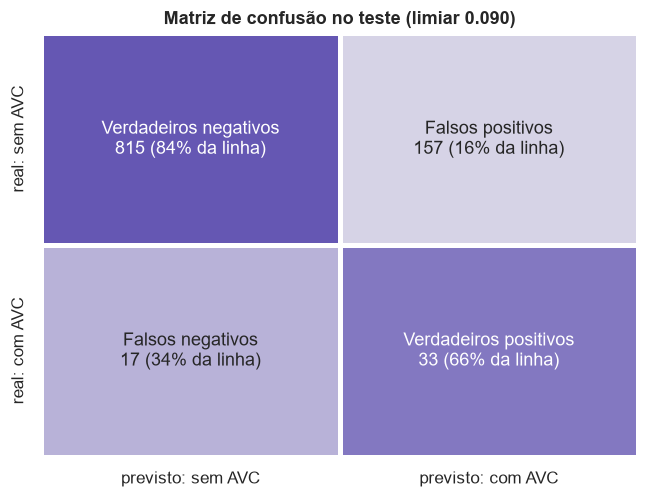

De 50 pacientes com AVC, o modelo sinaliza 33 e deixa passar 17.
De 190 alertas, 33 são AVC: 1 caso a cada 5.8 alertas.


In [6]:
matriz = confusion_matrix(y_test, previsto)
nomes_celula = np.array([["Verdadeiros negativos", "Falsos positivos"], ["Falsos negativos", "Verdadeiros positivos"]])
anotacoes = [[f"{nomes_celula[i, j]}\n{matriz[i, j]} ({matriz[i, j] / matriz[i].sum():.0%} da linha)" for j in range(2)]
             for i in range(2)]

# Cor = proporção dentro da linha (classe real), para a classe rara não sumir
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(matriz / matriz.sum(axis=1, keepdims=True), annot=anotacoes, fmt="", cmap=sns.light_palette(VIOLETA, as_cmap=True),
            vmin=0, vmax=1, cbar=False, linewidths=2, linecolor="white", ax=ax,
            xticklabels=["previsto: sem AVC", "previsto: com AVC"], yticklabels=["real: sem AVC", "real: com AVC"])
ax.set(title=f"Matriz de confusão no teste (limiar {LIMIAR:.3f})")
plt.show()

vn, fp, fn, vp = matriz.ravel()
print(f"De {vp + fn} pacientes com AVC, o modelo sinaliza {vp} e deixa passar {fn}.")
print(f"De {vp + fp} alertas, {vp} são AVC: 1 caso a cada {(vp + fp) / vp:.1f} alertas.")

In [7]:
# Perfil de cada célula da matriz: quem o modelo acerta e quem ele erra
grupo = np.select([(y_test == 1) & previsto, (y_test == 1) & ~previsto, (y_test == 0) & previsto],
                  ["verdadeiro positivo", "falso negativo", "falso positivo"], "verdadeiro negativo")
X_test.assign(grupo=grupo).groupby("grupo").agg(
    pacientes=("age", "size"), idade_mediana=("age", "median"), glicose_mediana=("avg_glucose_level", "median"),
    hipertensão_pct=("hypertension", lambda s: s.mean() * 100), doença_cardíaca_pct=("heart_disease", lambda s: s.mean() * 100),
    imc_ausente_pct=("bmi", lambda s: s.isna().mean() * 100),
).loc[["verdadeiro positivo", "falso negativo", "falso positivo", "verdadeiro negativo"]].round(1)

,pacientes,idade_mediana,glicose_mediana,hipertensão_pct,doença_cardíaca_pct,imc_ausente_pct
grupo,,,,,,
verdadeiro positivo,33,78.0,133.2,33.3,33.3,6.1
falso negativo,17,57.0,92.6,5.9,0.0,5.9
falso positivo,157,74.0,151.2,40.1,14.0,14.0
verdadeiro negativo,815,38.0,89.2,4.4,1.3,1.6


**Falsos negativos (17):** pacientes com AVC que o modelo não sinaliza. São mais jovens (mediana de 57 anos, contra 78 dos verdadeiros positivos) e quase sem fatores de risco registrados: 6% com hipertensão, nenhum com doença cardíaca e glicose mediana normal (93). O modelo não erra ao acaso: erra nos AVCs atípicos, que as features disponíveis não distinguem de pacientes saudáveis.

**Falsos positivos (157):** pacientes sem AVC sinalizados. Têm o perfil de risco dos verdadeiros positivos (mediana de 74 anos, 40% hipertensos, glicose mediana de 151) e são o grupo com mais IMC ausente (14%, contra 6% dos verdadeiros positivos): o indicador empurra pacientes sem AVC para cima do limiar. Pelo que o dataset registra, a maioria é de pacientes de alto risco que não tiveram AVC, ou ainda não tiveram; em triagem, é o erro aceitável, porque são os que mais se beneficiariam de acompanhamento.

O custo prático: para encontrar 33 dos 50 casos, o modelo sinaliza 190 pacientes (19% do teste), quase 6 alertas por caso verdadeiro.

### 2.3 Curva ROC

A curva ROC mostra a taxa de verdadeiros positivos (recall) contra a de falsos positivos em todos os limiares. A ROC-AUC é a probabilidade de um paciente com AVC sorteado receber probabilidade maior que um paciente sem AVC sorteado. Ao lado está a curva precisão-recall, que corresponde à métrica de seleção. O ponto laranja é o limiar escolhido.

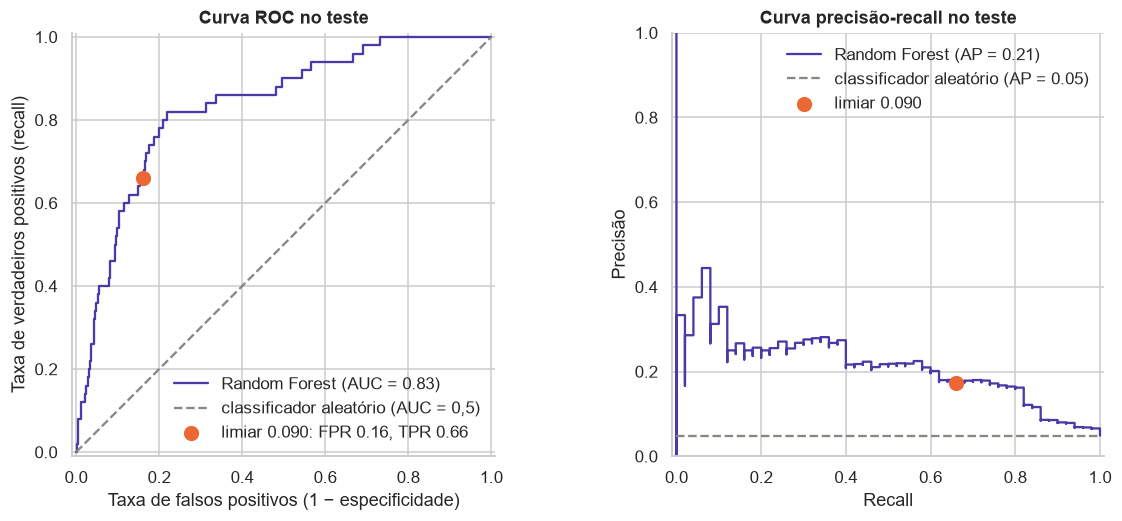

ROC-AUC no teste: 0.835


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Curva ROC com o ponto de operação do limiar escolhido
RocCurveDisplay.from_predictions(y_test, proba, name="Random Forest", curve_kwargs={"color": VIOLETA}, ax=axes[0],
                                 plot_chance_level=True,
                                 chance_level_kw={"color": CINZA, "ls": "--", "label": "classificador aleatório (AUC = 0,5)"})
fpr_ponto, tpr_ponto = fp / (fp + vn), vp / (vp + fn)
axes[0].scatter(fpr_ponto, tpr_ponto, color=LARANJA, s=80, zorder=3,
                label=f"limiar {LIMIAR:.3f}: FPR {fpr_ponto:.2f}, TPR {tpr_ponto:.2f}")
axes[0].set(title="Curva ROC no teste", xlabel="Taxa de falsos positivos (1 − especificidade)",
            ylabel="Taxa de verdadeiros positivos (recall)")
axes[0].legend(loc="lower right")

# Curva precisão-recall, correspondente à métrica de seleção
PrecisionRecallDisplay.from_predictions(y_test, proba, name="Random Forest", curve_kwargs={"color": VIOLETA}, ax=axes[1],
                                        plot_chance_level=True,
                                        chance_level_kw={"color": CINZA, "ls": "--",
                                                         "label": f"classificador aleatório (AP = {y_test.mean():.2f})"})
axes[1].scatter(tpr_ponto, vp / (vp + fp), color=LARANJA, s=80, zorder=3, label=f"limiar {LIMIAR:.3f}")
axes[1].set(title="Curva precisão-recall no teste", xlabel="Recall", ylabel="Precisão", ylim=(0, 1))
axes[1].legend(loc="upper right")
plt.show()

print(f"ROC-AUC no teste: {roc_auc_score(y_test, proba):.3f}")

**ROC-AUC = 0,835:** em 83,5% dos pares (paciente com AVC, paciente sem AVC), o paciente com AVC recebe probabilidade maior. A curva sobe rápido no início: com 20% de falsos positivos já chega a ~80% de recall. O ponto de operação (16% de falsos positivos, 66% de recall) fica nesse trecho de melhor custo-benefício.

**A curva precisão-recall mostra o outro lado:** a precisão fica entre 0,2 e 0,3 até 40% de recall e cai depois. A diferença entre as duas curvas é o efeito do desbalanceamento: 16% de falsos positivos parece pouco, mas são 157 pacientes, quase 5 vezes os 33 verdadeiros positivos. É por isso que a PR-AUC foi a métrica de seleção.

# Seção 3 — Interpretação e explicabilidade

### 3.1 Regressão logística: coeficientes de maior magnitude

O modelo linear é a regressão logística ajustada no notebook 03 (L1, C = 0,32), com o pipeline da APS1. Cada coeficiente é a mudança no log da chance de AVC quando a feature aumenta uma unidade, com as demais fixas.

**Cuidado com a escala.** As contínuas foram padronizadas na APS1 (desvio 1), mas as binárias e o one-hot ficaram em 0/1, com desvio bem menor que 1 (0,20 no IMC ausente, 0,29 na hipertensão). Assim, um coeficiente de binária mede um salto de 0 a 1, que equivale a vários desvios padrão dela, e comparar coeficientes brutos favorece as binárias. Para comparar numa escala comum, o gráfico da direita multiplica cada coeficiente pelo desvio padrão da feature no treino: é o efeito de +1 desvio em qualquer feature. **O top 3 é definido por essa escala comum.**

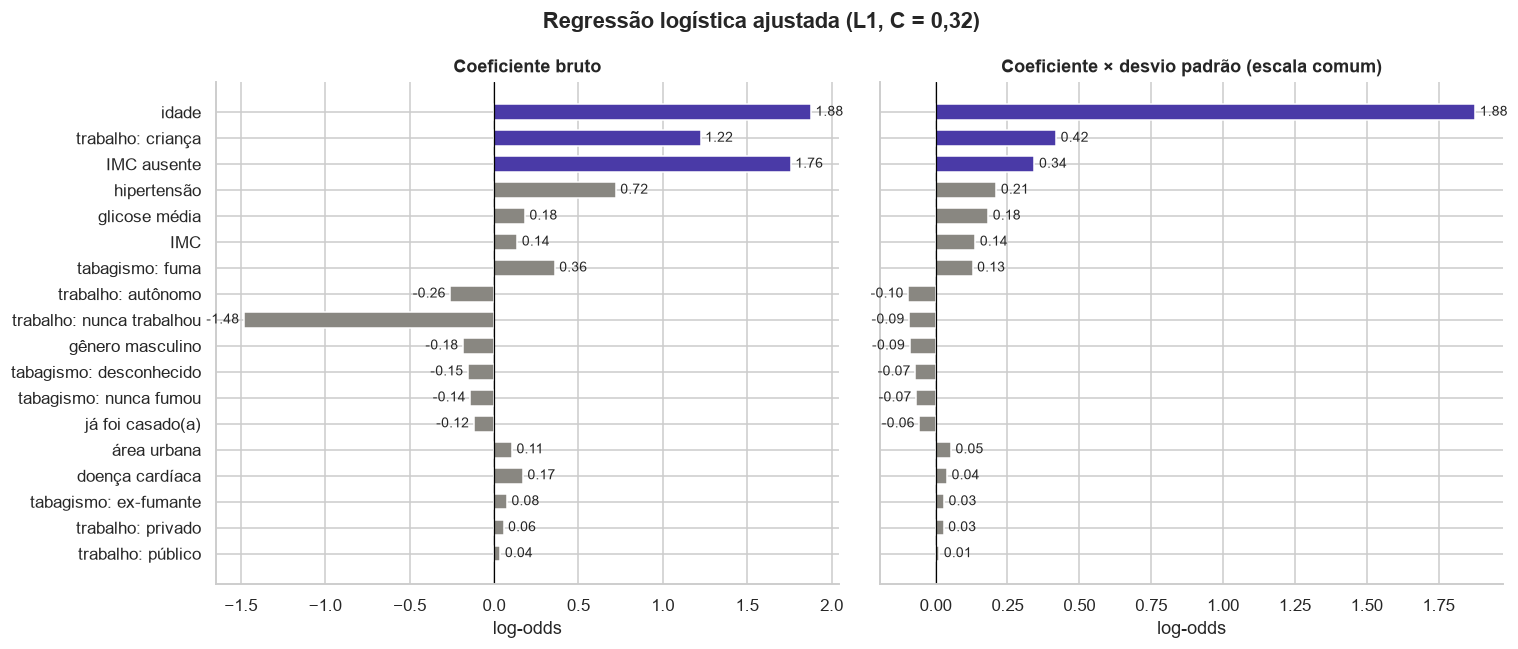

Coeficientes zerados pela penalidade L1: 0 de 18: 


,coeficiente,desvio da feature,coef × desvio,razão de chances exp(coef)
idade,1.88,1.00,1.88,6.53
trabalho: criança,1.22,0.34,0.42,3.40
IMC ausente,1.76,0.20,0.34,5.80
hipertensão,0.72,0.29,0.21,2.06


In [9]:
# Coeficientes brutos e coeficiente × desvio padrão da feature no treino (efeito de +1 desvio, escala comum)
X_train_lr = logistica["prep"].transform(X_train)
coeficientes = pd.DataFrame({"coeficiente": logistica["modelo"].coef_[0], "desvio da feature": X_train_lr.std()},
                            index=X_train_lr.columns)
coeficientes["coef × desvio"] = coeficientes["coeficiente"] * coeficientes["desvio da feature"]
coeficientes = coeficientes.rename(index=ROTULOS)
ordem = coeficientes["coef × desvio"].abs().sort_values(ascending=False).index
top3_lr = ordem[:3]

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
for ax, col, titulo in [(axes[0], "coeficiente", "Coeficiente bruto"),
                        (axes[1], "coef × desvio", "Coeficiente × desvio padrão (escala comum)")]:
    ax.barh(ordem, coeficientes.loc[ordem, col], color=[VIOLETA if f in top3_lr else CINZA for f in ordem], height=0.6)
    ax.bar_label(ax.containers[0], fmt="%.2f", padding=3, fontsize=9)
    ax.axvline(0, color="black", lw=0.8)
    ax.set(title=titulo, xlabel="log-odds")
axes[0].invert_yaxis()
fig.suptitle("Regressão logística ajustada (L1, C = 0,32)", fontweight="bold")
plt.tight_layout()
plt.show()

zerados = coeficientes.index[coeficientes["coeficiente"] == 0]
print(f"Coeficientes zerados pela penalidade L1: {len(zerados)} de {len(coeficientes)}:", ", ".join(zerados))
coeficientes.loc[ordem[:4]].assign(**{"razão de chances exp(coef)": lambda d: np.exp(d["coeficiente"])}).round(2)

**As 3 features de maior magnitude (coeficiente × desvio padrão):**

1. **Idade (1,57; razão de chances 4,8 a cada 22,6 anos):** de longe o maior efeito, como a APS1 antecipava (mediana de 70 anos nos casos contra 43).
2. **IMC ausente (0,26; razão de chances 3,8 para quem não tem IMC):** não é efeito biológico. É o sinal da tarefa 1.5 da APS1 (19,9% de AVC entre quem não tem IMC), preservado pelo indicador criado no pré-processamento. A seção 4.1 mostra que esse sinal quase desaparece no teste.
3. **Glicose média (0,17; razão de chances 1,18 a cada desvio de log-glicose):** a logística só consegue um efeito linear em log-glicose, e por isso aproveita pouco o grupo com glicose acima de 170, que a APS1 apontava como o de maior risco.

Pelos coeficientes brutos, a **hipertensão** (0,38) estaria em 3º, à frente da glicose: é exatamente o efeito de escala descrito acima. Na escala comum ela fica em 4º (0,11).

**Doença cardíaca zerada.** A penalidade L1 zerou 6 coeficientes, entre eles gênero e três colunas de trabalho (a mesma direção da mudança de pipeline da seção 1.5, obtida de forma independente) e a doença cardíaca, que a APS1 apontava como fator de risco. Há dois motivos: parte do efeito dela já está na idade e na hipertensão, e, com desvio de só 0,23, ela precisaria de um coeficiente cerca de 4 vezes maior que uma contínua para ter o mesmo efeito, o que a penalidade L1 pune proporcionalmente. O zero não quer dizer que a doença cardíaca não importa.

**As razões de chances estão encolhidas.** Num modelo penalizado, os coeficientes são puxados para zero, e as razões de chances, para 1. Os valores acima são, portanto, estimativas conservadoras do efeito, não as de uma regressão sem penalidade.

### 3.2 Random Forest: features de maior importância

O ensemble é a Random Forest final. A importância por impureza (`feature_importances_`) mede quanto cada feature reduz o índice de Gini nas divisões, em média sobre as árvores. Ela é calculada no treino e tende a favorecer variáveis contínuas, que oferecem mais pontos de corte (Strobl et al., 2007). Por isso o gráfico da direita confere o resultado com a importância por permutação no teste: quanto a PR-AUC cai quando os valores de uma variável original são embaralhados.

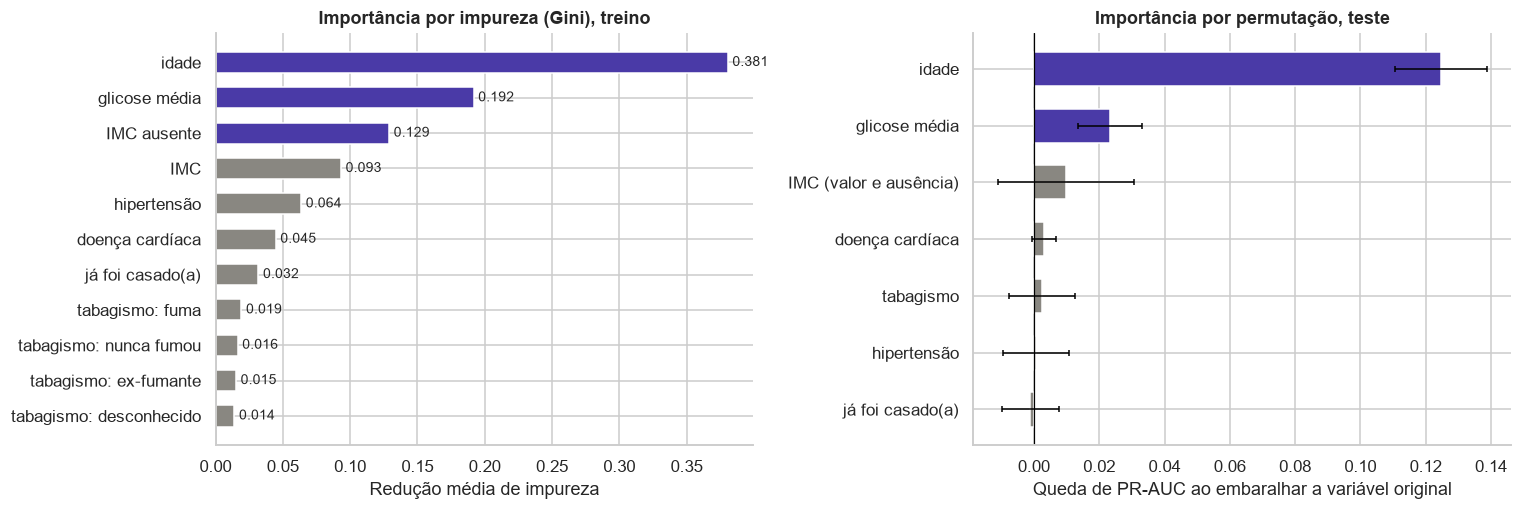

,importância (impureza),queda média de PR-AUC,desvio
idade,0.381,0.125,0.014
glicose média,0.192,0.023,0.010
IMC ausente,0.129,0.010,0.021


In [10]:
prep, floresta = pipeline_rf["prep"], pipeline_rf["modelo"]
nomes_rf = pd.Index(prep.get_feature_names_out()).map(lambda f: ROTULOS.get(f, f))
importancia = pd.Series(floresta.feature_importances_, index=nomes_rf).sort_values(ascending=False)

# Permuta as variáveis originais usadas pelo modelo; embaralhar o bmi embaralha também a sua ausência
ORIGINAIS = {"age": "idade", "avg_glucose_level": "glicose média", "bmi": "IMC (valor e ausência)",
             "hypertension": "hipertensão", "heart_disease": "doença cardíaca", "ever_married": "já foi casado(a)",
             "smoking_status": "tabagismo"}
permutacao = permutation_importance(pipeline_rf, X_test, y_test, scoring="average_precision", n_repeats=30,
                                    random_state=RANDOM_STATE, n_jobs=-1)
importancia_perm = (pd.DataFrame({"queda média de PR-AUC": permutacao.importances_mean, "desvio": permutacao.importances_std},
                                 index=X_test.columns).loc[list(ORIGINAIS)].rename(ORIGINAIS)
                    .sort_values("queda média de PR-AUC", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].barh(importancia.index, importancia, color=[VIOLETA] * 3 + [CINZA] * (len(importancia) - 3), height=0.6)
axes[0].bar_label(axes[0].containers[0], fmt="%.3f", padding=3, fontsize=9)
axes[0].set(title="Importância por impureza (Gini), treino", xlabel="Redução média de impureza")
axes[1].barh(importancia_perm.index, importancia_perm["queda média de PR-AUC"], xerr=importancia_perm["desvio"],
             color=[VIOLETA] * 2 + [CINZA] * (len(importancia_perm) - 2), height=0.6,
             error_kw={"ecolor": "black", "capsize": 2, "lw": 1})
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set(title="Importância por permutação, teste", xlabel="Queda de PR-AUC ao embaralhar a variável original")
for ax in axes:
    ax.invert_yaxis()
plt.tight_layout()
plt.show()

importancia.head(3).to_frame("importância (impureza)").join(importancia_perm.round(4).rename(
    index={"IMC (valor e ausência)": "IMC ausente"})).round(3)

**As 3 features mais importantes por impureza:**

1. **Idade (0,381):** quase 40% de toda a redução de impureza. A permutação confirma: embaralhar a idade derruba a PR-AUC do teste em 0,125, mais da metade do valor do modelo.
2. **Glicose média (0,192):** o grupo com glicose alta, mantido como outlier na APS1, é o segundo sinal mais forte. A permutação também a coloca em 2º (queda de 0,023).
3. **IMC ausente (0,129):** importante no treino, mas **no teste embaralhar o IMC (e a sua ausência) tira só 0,010 ± 0,021 da PR-AUC**, ou seja, nada distinguível de zero. As duas medidas não se contradizem: a impureza mostra o que o modelo aprendeu no treino, e a permutação mostra que esse aprendizado não rende no teste, onde o sinal da ausência quase some (seção 4.1).

As demais features ficam perto de zero na permutação: individualmente, hipertensão e doença cardíaca acrescentam pouco a um modelo que já sabe a idade e a glicose. O IMC contínuo aparece em 4º por impureza (0,093) porque oferece muitos cortes possíveis, um exemplo do viés descrito por Strobl et al. (2007).

### 3.3 SHAP: importância global e explicação de predições individuais

SHAP divide a diferença entre a predição de um paciente e a predição média entre as features, usando os valores de Shapley da teoria dos jogos (Lundberg & Lee, 2017). Para florestas, o TreeExplainer calcula esses valores de forma exata e rápida (Lundberg et al., 2020). Aqui estão na escala de probabilidade: o valor base é 0,049 (a probabilidade média) e, para cada paciente, valor base + soma dos SHAP = probabilidade prevista, o que a célula abaixo verifica. O SHAP explica o que o **modelo** faz, não o que é verdade nos dados.

In [11]:
# TreeExplainer na floresta, sobre as features já transformadas; [:, :, 1] = classe AVC
X_test_prep = prep.transform(X_test)
explicacao = shap.TreeExplainer(floresta)(X_test_prep)[:, :, 1]
explicacao.feature_names = list(nomes_rf)

# Os valores exibidos ficam na escala original (anos, mg/dL, kg/m²); a floresta é invariante a log e padronização
explicacao.data = X_test_prep.assign(age=X_test["age"].to_numpy(), avg_glucose_level=X_test["avg_glucose_level"].to_numpy(),
                                     bmi=X_test["bmi"].to_numpy()).to_numpy()

# Propriedade de aditividade: valor base + soma dos SHAP = probabilidade prevista
soma = explicacao.base_values + explicacao.values.sum(axis=1)
print(f"Valor base (probabilidade média no treino): {explicacao.base_values[0]:.3f}")
print(f"Maior diferença entre valor base + soma dos SHAP e a probabilidade prevista: {np.abs(soma - proba).max():.1e}")

Valor base (probabilidade média no treino): 0.049
Maior diferença entre valor base + soma dos SHAP e a probabilidade prevista: 6.1e-16


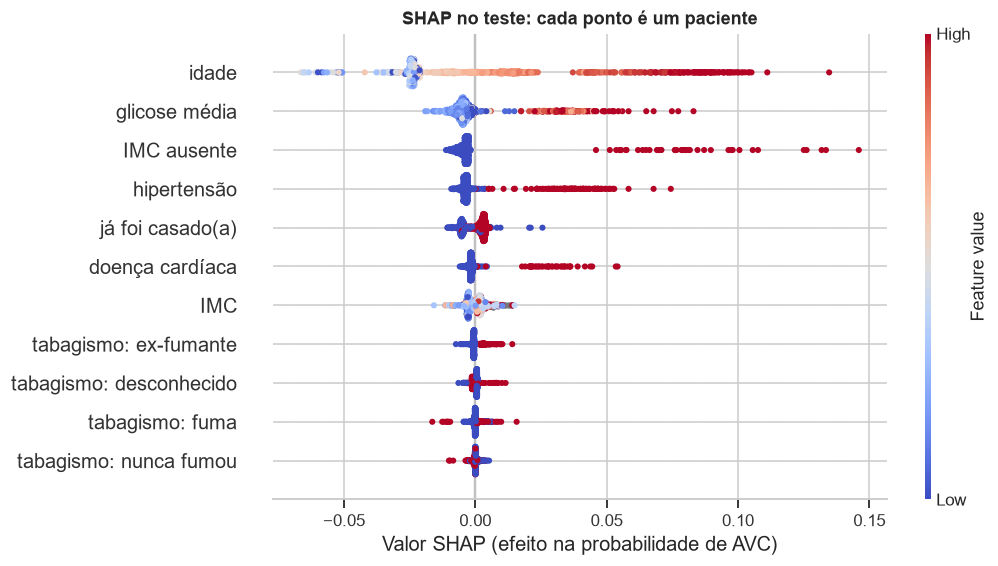

In [12]:
shap.plots.beeswarm(explicacao, max_display=11, color=plt.get_cmap("coolwarm"), show=False, plot_size=(9, 5.5))
plt.title("SHAP no teste: cada ponto é um paciente", fontweight="bold")
plt.xlabel("Valor SHAP (efeito na probabilidade de AVC)")
plt.show()

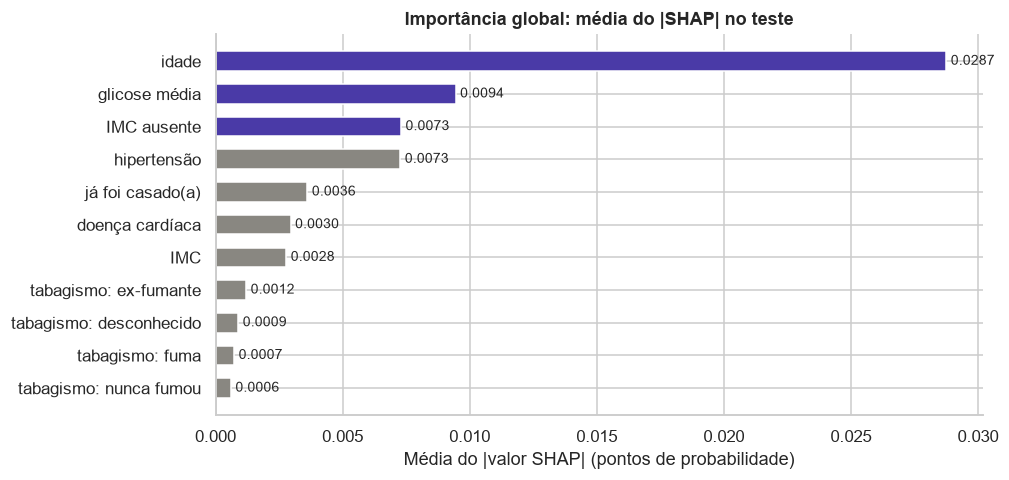

In [13]:
shap_medio = pd.Series(np.abs(explicacao.values).mean(axis=0), index=nomes_rf).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(shap_medio.index, shap_medio, color=[VIOLETA] * 3 + [CINZA] * (len(shap_medio) - 3), height=0.6)
ax.bar_label(ax.containers[0], fmt="%.4f", padding=3, fontsize=9)
ax.invert_yaxis()
ax.set(title="Importância global: média do |SHAP| no teste", xlabel="Média do |valor SHAP| (pontos de probabilidade)")
plt.show()

**Importância global.** Na média do |SHAP| a ordem é idade, glicose, IMC ausente e hipertensão: as três primeiras são as mesmas da importância por impureza. O beeswarm mostra também a direção e a forma de cada efeito:

- **idade:** idades baixas (azul) tiram até ~0,07 da probabilidade e idades altas (vermelho) somam até ~0,13. O efeito cresce acelerado entre os mais velhos, a não linearidade que a APS1 descrevia (quase nenhum AVC antes dos 40);
- **glicose:** só os valores altos empurram a predição para cima; os normais quase não mexem. É o efeito de limiar visto na APS1, que a regressão logística, linear na log-glicose, não captura;
- **IMC ausente:** para os 38 pacientes sem IMC, o modelo soma de +0,05 a +0,15, o maior empurrão individual que ele dá. Mas só 3 desses 38 tiveram AVC (7,9%): o modelo prevê em média 13,8% para esse grupo e sinaliza 24 dos 38, então superestima o grupo no teste. Isso explica a importância por permutação nula e parte dos falsos positivos;
- **hipertensão e doença cardíaca:** ter a condição soma até ~0,07; não ter quase não muda nada;
- **IMC e tabagismo:** efeitos pequenos e misturados, coerentes com a APS1.

**Predições individuais.** Três pacientes do teste, escolhidos para cobrir o acerto e os dois tipos de erro: o verdadeiro positivo com maior probabilidade (o perfil típico de risco), o falso negativo **mais perto do limiar** (o erro que um ajuste fino poderia evitar) e o falso positivo com maior probabilidade (o falso alarme mais forte).

In [14]:
# Três pacientes: um acerto claro, o erro mais caro perto da fronteira e o falso alarme mais forte
vp_mask, fn_mask, fp_mask = (y_test == 1) & previsto, (y_test == 1) & ~previsto, (y_test == 0) & previsto
casos = {
    "verdadeiro positivo": np.flatnonzero(vp_mask)[proba[vp_mask].argmax()],         # maior probabilidade
    "falso negativo": np.flatnonzero(fn_mask)[proba[fn_mask].argmax()],              # mais perto do limiar
    "falso positivo": np.flatnonzero(fp_mask)[proba[fp_mask].argmax()],              # maior probabilidade
}
indices = list(casos.values())
X_test.iloc[indices].assign(caso=list(casos), AVC_real=y_test.iloc[indices].to_numpy(),
                            probabilidade=proba[indices].round(3)).set_index("caso")

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,AVC_real,probabilidade
caso,,,,,,,,,,,,
verdadeiro positivo,Male,78.0,0,1,Yes,Private,Urban,219.84,NaN,Unknown,1,0.305
falso negativo,Male,57.0,1,0,Yes,Govt_job,Urban,78.92,27.7,formerly smoked,1,0.090
falso positivo,Male,78.0,1,0,Yes,Self-employed,Urban,90.19,NaN,Unknown,0,0.336


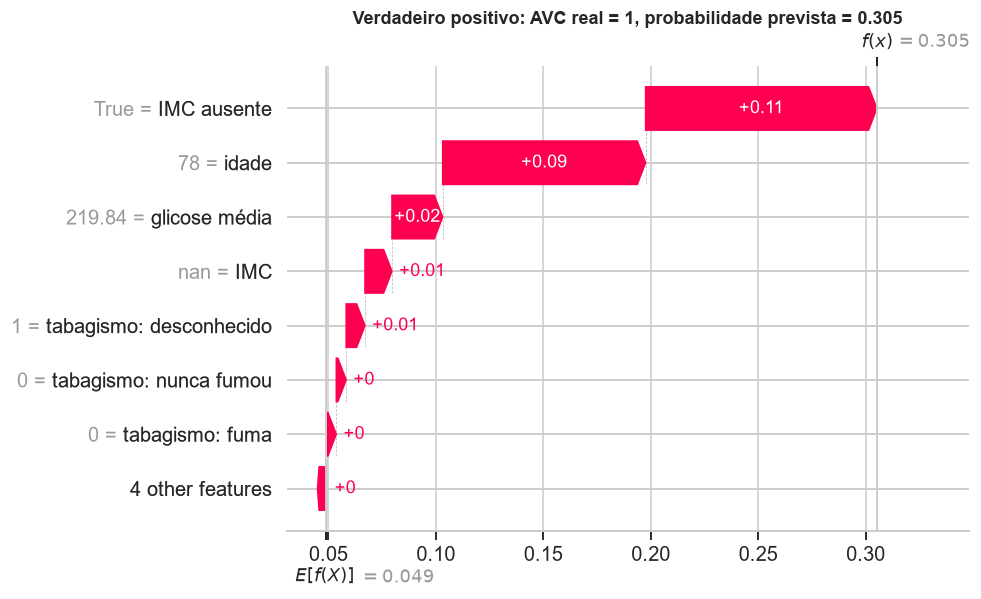

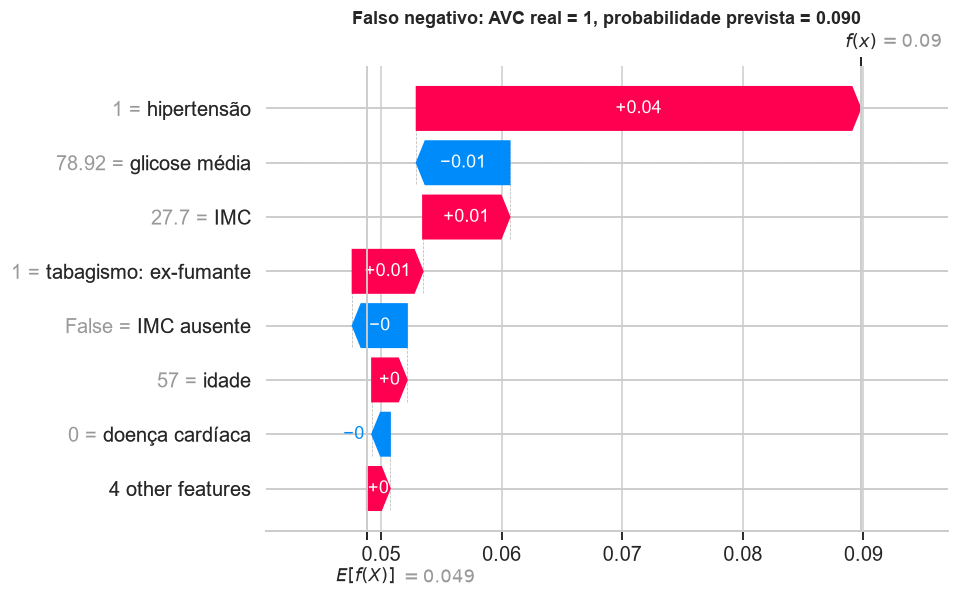

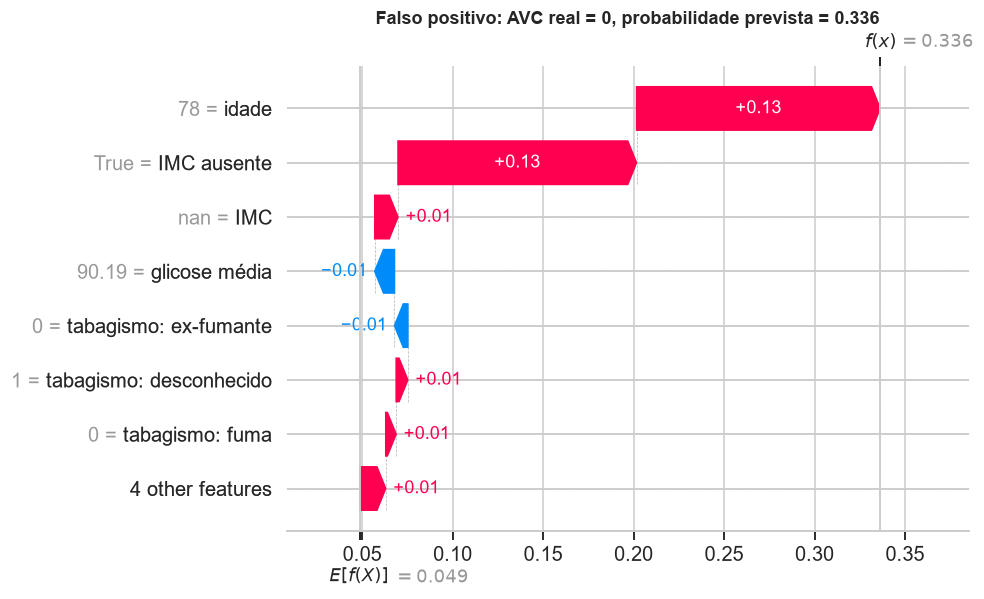

In [15]:
for nome, i in casos.items():
    shap.plots.waterfall(explicacao[i], max_display=8, show=False)
    plt.title(f"{nome.capitalize()}: AVC real = {y_test.iloc[i]}, probabilidade prevista = {proba[i]:.3f}", fontweight="bold")
    plt.show()

Cada gráfico parte do valor base (0,049, embaixo) e soma a contribuição de cada feature até a probabilidade prevista (em cima). Os valores estão na escala original; "nan" no IMC indica ausência, e o modelo vê nesse lugar a mediana imputada.

1. **Verdadeiro positivo (homem, 78 anos, doença cardíaca, glicose 220, sem IMC; probabilidade 0,305):** as maiores contribuições são IMC ausente (+0,11), idade (+0,09) e glicose (+0,02). É o perfil de alto risco descrito na APS1, com probabilidade 6 vezes a média. A doença cardíaca quase não contribui (está entre as "4 other features"): nas árvores rasas, idade e glicose já separam esse paciente.
2. **Falso negativo (homem, 57 anos, hipertenso, ex-fumante, glicose 79, IMC 27,7; probabilidade 0,0898):** ficou a 0,0003 do limiar (0,0901). A hipertensão soma +0,04 e o tabagismo e o IMC somam um pouco; a glicose normal tira 0,01, e a idade, perto da média do dataset, quase não conta. É o perfil intermediário em que o modelo hesita: um fator de risco forte, sem idade avançada nem glicose alta. Não é um caso isolado: 4 dos 17 falsos negativos ficaram a menos de 0,005 do limiar, o que mostra o quanto o recall é sensível à escolha exata do limiar.
3. **Falso positivo (homem, 78 anos, hipertenso, glicose 90, sem IMC; probabilidade 0,336):** idade (+0,13) e IMC ausente (+0,13) explicam quase toda a probabilidade, e a glicose normal tira um pouco (−0,01). É o paciente sem AVC com maior probabilidade do teste, e metade dela vem da falta de um dado.

Os casos 1 e 3 recebem probabilidades parecidas pelos mesmos motivos (idade e IMC ausente), e só um teve AVC: o modelo ordena risco, mas não diagnostica.

# Seção 4 — Discussão crítica

### 4.1 Limitações do modelo

Duas limitações do modelo que as seções anteriores não mostraram.

**1. O modelo depende de um sinal que não se repete no teste: a ausência do IMC.** No notebook 03 (seção 1.5), tirar o indicador de IMC ausente derrubava a PR-AUC da validação cruzada de 0,264 para 0,195. A célula abaixo compara a taxa de AVC com e sem IMC no treino e no teste e, só como diagnóstico, mede no teste o mesmo pipeline sem o indicador.

In [16]:
# Taxa de AVC com e sem IMC registrado, no treino e no teste
taxa_imc = pd.concat({nome: d.groupby(d["bmi"].isna().map({False: "com IMC", True: "sem IMC"}))[TARGET]
                      .agg(pacientes="size", casos_avc="sum", taxa_avc=lambda s: s.mean() * 100)
                      for nome, d in [("treino", train), ("teste", test)]}).round(1)

# Diagnóstico (não é seleção de modelo): o mesmo pipeline sem o indicador, treinado no treino e medido no teste
pipeline_sem_indicador = clone(pipeline_rf).set_params(
    prep__transformers=[ramo for ramo in pipeline_rf["prep"].transformers if ramo[0] != "imc_ausente"])
proba_sem_indicador = pipeline_sem_indicador.fit(X_train, y_train).predict_proba(X_test)[:, 1]
print(f"PR-AUC no teste: com indicador {average_precision_score(y_test, proba):.3f}, "
      f"sem indicador {average_precision_score(y_test, proba_sem_indicador):.3f}")
taxa_imc

PR-AUC no teste: com indicador 0.214, sem indicador 0.264


pacientes  casos_avc  taxa_avc
       bmi                                    
treino com IMC       3924        162       4.1
       sem IMC        163         37      22.7
teste  com IMC        984         47       4.8
       sem IMC         38          3       7.9

- No treino, quem não tem IMC tem **22,7%** de AVC (37 de 163), mais de 5 vezes os 4,1% de quem tem. No teste, são **7,9%** (3 de 38), quase o mesmo que os 4,8% de quem tem. O sinal que o modelo aprendeu praticamente não existe no teste.
- Sem o indicador, a mesma floresta teria PR-AUC de **0,264 no teste**, contra 0,214 com ele: o indicador, que ajudava na validação cruzada, atrapalha no teste. Isso explica a maior parte da queda de 0,269 para 0,214 vista na seção 2.1. Para esses 38 pacientes, o modelo prevê em média 13,8% de AVC, quase o dobro dos 7,9% reais, e sinaliza 24 deles.
- **O modelo final não é trocado por causa disso.** Escolher o pipeline sem o indicador agora seria selecionar modelo pelo teste, e o 0,264 deixaria de ser uma estimativa honesta. O resultado entra como limitação e como recomendação: com 163 pacientes sem IMC no treino (37 casos), a diferença entre 22,7% e 7,9% pode ser em parte acaso, mas um sinal tão forte, sem explicação clínica e instável entre amostras, não deveria sustentar um modelo em produção. A próxima versão deveria ser desenvolvida sem o indicador, ou com ele validado em dados novos.

**2. O ponto de operação só vale para a prevalência desta amostra.** Recall e especificidade são propriedades do modelo, mas a precisão (valor preditivo positivo) depende da proporção de AVC na população. A célula abaixo mantém o recall e a especificidade do teste e recalcula a precisão para prevalências menores, pelo teorema de Bayes, e mostra a calibração do modelo nesta amostra.

Recall 0.660 e especificidade 0.838 do teste, mantidos fixos


,prevalência (%),precisão (VPP),alertas por caso de AVC
"esta amostra (4,9%)",4.892,0.174,5.758
2%,2.000,0.077,12.992
1%,1.000,0.040,25.228
"0,5%",0.500,0.020,49.702
"0,15% (incidência anual global de AVC)",0.150,0.006,163.909


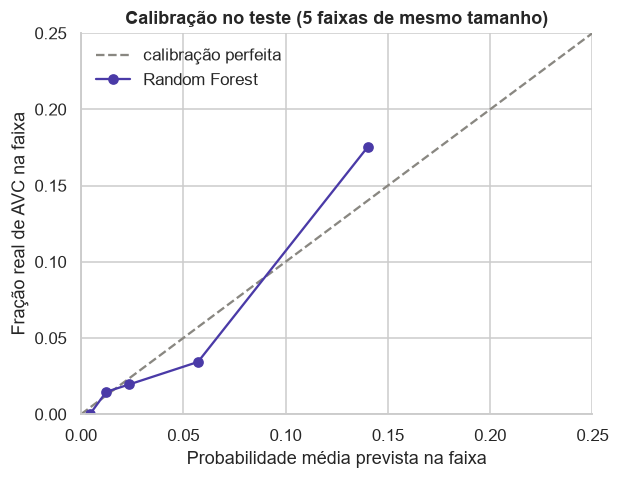

In [17]:
# Mesmo recall e especificidade do teste, aplicados a prevalências menores (teorema de Bayes)
recall_teste, especificidade_teste = vp / (vp + fn), vn / (vn + fp)
prevalencias = {"esta amostra (4,9%)": y_test.mean(), "2%": 0.02, "1%": 0.01, "0,5%": 0.005,
                "0,15% (incidência anual global de AVC)": 0.0015}
ppv = pd.DataFrame({"prevalência (%)": [p * 100 for p in prevalencias.values()]}, index=list(prevalencias))
p = np.array(list(prevalencias.values()))
ppv["precisão (VPP)"] = recall_teste * p / (recall_teste * p + (1 - especificidade_teste) * (1 - p))
ppv["alertas por caso de AVC"] = 1 / ppv["precisão (VPP)"]
print(f"Recall {recall_teste:.3f} e especificidade {especificidade_teste:.3f} do teste, mantidos fixos")
display(ppv.round(3))

# Calibração nesta amostra: probabilidade média prevista contra fração real de AVC, em 5 faixas de mesmo tamanho
fracao_real, proba_media = calibration_curve(y_test, proba, n_bins=5, strategy="quantile")
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot([0, 0.25], [0, 0.25], color=CINZA, ls="--", label="calibração perfeita")
ax.plot(proba_media, fracao_real, marker="o", color=VIOLETA, label="Random Forest")
ax.set(title="Calibração no teste (5 faixas de mesmo tamanho)", xlabel="Probabilidade média prevista na faixa",
       ylabel="Fração real de AVC na faixa", xlim=(0, 0.25), ylim=(0, 0.25))
ax.legend()
plt.show()

Numa população com 1% de AVC, o mesmo modelo com o mesmo limiar teria precisão de 4%: 25 alertas por caso. Com a incidência anual de AVC na população geral (cerca de 150 por 100 mil pessoas, segundo o GBD 2019; Feigin et al., 2021), seriam mais de 160 alertas por caso.

A curva de calibração mostra que, **nesta amostra**, as probabilidades são razoáveis: nas faixas baixas a previsão acompanha a fração real, e na faixa mais alta o modelo prevê 0,14 para uma fração real de 0,175, uma leve subestimação. Mas essa calibração está presa à prevalência de 4,9%, que mostra que a amostra não é uma população geral. Em outra população, as probabilidades ficariam superestimadas (Van Calster et al., 2019), e o limiar de 0,090 deixaria de significar o mesmo recall e a mesma precisão. Usar o modelo em outro contexto exige recalibrar as probabilidades e escolher de novo o limiar com dados dessa população.

### 4.2 Limitações dos dados

**1. Os dados são transversais: o target é histórico de AVC, não AVC futuro.** Não há datas, então não se sabe se hipertensão, glicose, IMC ou tabagismo foram medidos antes ou depois do AVC. Quem teve AVC pode ter passado a tratar a pressão, mudado a dieta ou parado de fumar ("ex-fumante" pode ser consequência). O modelo aprende associações com quem *teve* AVC, não fatores que o *precedem*, e não pode ser usado como previsão de risco futuro. Para isso são necessários dados longitudinais, como os da coorte de Framingham, base dos escores clássicos de risco de AVC (Wolf et al., 1991). A instabilidade do IMC ausente (seção 4.1) é compatível com isso: a falta de um peso medido pode refletir como cada paciente chegou ao registro (por exemplo, internado após o AVC), e não uma característica dele.

**2. Faltam fatores de risco centrais.** O estudo INTERSTROKE identificou dez fatores de risco modificáveis responsáveis por cerca de 90% do risco populacional de AVC: hipertensão, atividade física, relação ApoB/ApoA1, dieta, relação cintura-quadril, fatores psicossociais, tabagismo, causas cardíacas (como fibrilação atrial), álcool e diabetes (O'Donnell et al., 2016). O dataset tem versões grosseiras de poucos deles: hipertensão como sim/não em vez da pressão medida, doença cardíaca sem distinguir a fibrilação atrial, glicose média no lugar do diagnóstico de diabetes, IMC no lugar da relação cintura-quadril, e nada sobre colesterol, atividade física, dieta, álcool ou estresse. Isso explica o teto visto na curva de aprendizado (o modelo fica em 0,45 de PR-AUC até no treino) e os falsos negativos sem nenhum fator registrado.

### 4.3 Operacionalização e manutenção

**1. Monitorar entradas e desempenho, com recalibração e re-treino programados.** Em produção, a distribuição das entradas muda (outra população, novos protocolos de coleta) e o desempenho cai sem aviso; esse é um dos principais custos ocultos de sistemas de ML (Sculley et al., 2015). Na prática:

- comparar todo mês a distribuição de cada feature com a do treino, por testes univariados (Kolmogorov-Smirnov nas contínuas, qui-quadrado nas categóricas, com correção de Bonferroni), que Rabanser et al. (2019) mostraram ser um detector de mudança simples e eficaz. A taxa de IMC ausente e a taxa de AVC nesse grupo merecem alarme próprio, pela seção 4.1;
- acompanhar a taxa de alertas (19% no teste): uma mudança brusca indica mudança na população ou no fluxo de dados antes mesmo de os desfechos chegarem;
- quando os desfechos reais chegarem, recalcular recall, precisão e calibração. Abaixo de um recall mínimo acordado (por exemplo, 53%, o limite inferior do intervalo de confiança do teste), recalibrar ou retreinar com os dados novos.

**2. Versionar o pipeline como um artefato único, com um model card.** O objeto salvo no notebook 03 já reúne pré-processamento, modelo e limiar; ele deve ser versionado junto com os dados e o código que o geraram, para que toda predição seja rastreável a uma versão e um re-treino possa ser desfeito. Cada versão deve vir com um model card (Mitchell et al., 2019) que registre a população em que o modelo vale, as métricas com intervalos de confiança, o limiar e o motivo da escolha, e as limitações desta seção.

## Referências

- Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5–32.
- Collins, G. S., Ogundimu, E. O., & Altman, D. G. (2016). Sample size considerations for the external validation of a multivariable prognostic model: a resampling study. *Statistics in Medicine*, 35(2), 214–226.
- Feigin, V. L. et al. (GBD 2019 Stroke Collaborators) (2021). Global, regional, and national burden of stroke and its risk factors, 1990–2019: a systematic analysis for the Global Burden of Disease Study 2019. *The Lancet Neurology*, 20(10), 795–820.
- Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems*, 30.
- Lundberg, S. M., Erion, G., Chen, H. et al. (2020). From local explanations to global understanding with explainable AI for trees. *Nature Machine Intelligence*, 2(1), 56–67.
- Mitchell, M. et al. (2019). Model cards for model reporting. *Proceedings of the Conference on Fairness, Accountability, and Transparency (FAT\* '19)*, 220–229.
- O'Donnell, M. J. et al. (2016). Global and regional effects of potentially modifiable risk factors associated with acute stroke in 32 countries (INTERSTROKE): a case-control study. *The Lancet*, 388(10046), 761–775.
- Rabanser, S., Günnemann, S., & Lipton, Z. C. (2019). Failing loudly: an empirical study of methods for detecting dataset shift. *Advances in Neural Information Processing Systems*, 32.
- Sculley, D. et al. (2015). Hidden technical debt in machine learning systems. *Advances in Neural Information Processing Systems*, 28, 2503–2511.
- Strobl, C., Boulesteix, A.-L., Zeileis, A., & Hothorn, T. (2007). Bias in random forest variable importance measures: illustrations, sources and a solution. *BMC Bioinformatics*, 8, 25.
- Van Calster, B., McLernon, D. J., van Smeden, M., Wynants, L., & Steyerberg, E. W. (2019). Calibration: the Achilles heel of predictive analytics. *BMC Medicine*, 17, 230.
- Wolf, P. A., D'Agostino, R. B., Belanger, A. J., & Kannel, W. B. (1991). Probability of stroke: a risk profile from the Framingham Study. *Stroke*, 22(3), 312–318.